In [9]:
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense,Conv2D,Activation,Dropout,Flatten,MaxPooling2D
from tensorflow.keras.datasets import fashion_mnist
from tensorflow.keras.utils import to_categorical
from scikeras.wrappers import KerasClassifier
import seaborn as sns
from sklearn.metrics import confusion_matrix

In [10]:
(x_train_digit,y_train_digit),(x_test_digit,y_test_digit) = fashion_mnist.load_data()
print("x_train:",x_train_digit.shape)
print("y_train:",y_train_digit.shape)
print("x_test:",x_test_digit.shape)
print("y_test:",y_test_digit.shape)

x_train: (60000, 28, 28)
y_train: (60000,)
x_test: (10000, 28, 28)
y_test: (10000,)


In [4]:
x_train_digit

array([[[0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        ...,
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0]],

       [[0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        ...,
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0]],

       [[0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        ...,
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0]],

       ...,

       [[0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        ...,
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0]],

       [[0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        ...,
        [0, 0, 0, ..., 

In [5]:
y_train_digit

array([9, 0, 0, ..., 3, 0, 5], shape=(60000,), dtype=uint8)

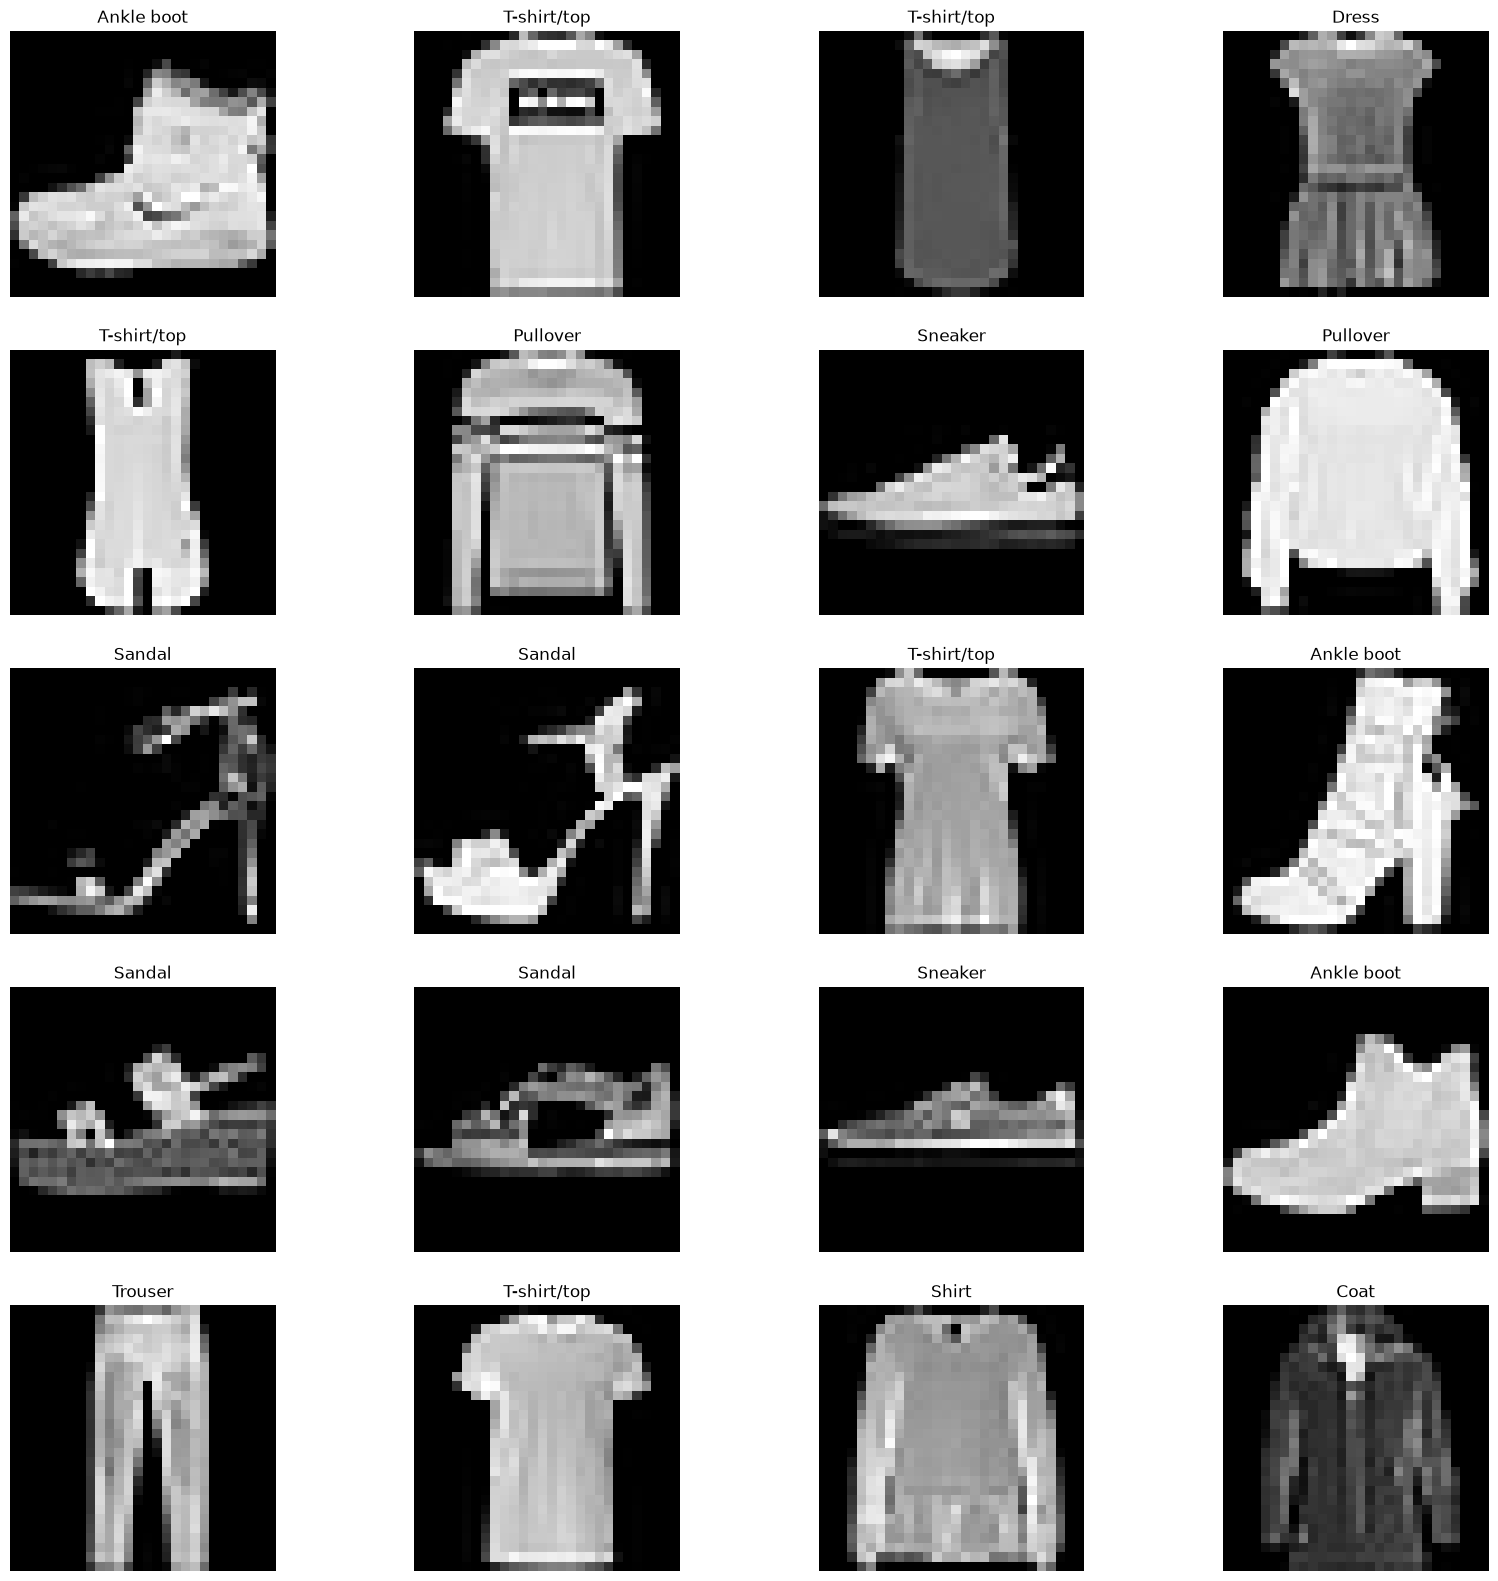

In [7]:
mnist_names = [
    "T-shirt/top","Trouser","Pullover","Dress","Coat","Sandal","Shirt","Sneaker","Bag","Ankle boot"
]	
plt.figure(figsize=(20, 20))
for i in range(20):
    plt.subplot(5, 4, i + 1)
    plt.axis('off')
    plt.grid(False)
    plt.imshow(x_train_digit[i], cmap='gray')
    plt.title(mnist_names[y_train_digit[i]])
plt.show()

In [11]:
x_train=x_train_digit.reshape(x_train_digit.shape[0],28,28,1)
x_test=x_test_digit.reshape(x_test_digit.shape[0],28,28,1)

In [12]:
x_train=x_train.astype('float32')
x_test=x_test.astype('float32')

In [13]:
x_train /= 255
x_test /= 255

In [17]:
model=Sequential()
model.add(Conv2D(28,kernel_size=(3,3),input_shape=(28,28,1),activation='relu'))
model.add(MaxPooling2D(pool_size=(2,2)))
model.add(Flatten())
model.add(Dense(128,activation=tf.nn.relu))
model.add(Dense(10,activation=tf.nn.softmax))

In [20]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [21]:
history = model.fit(
    x_train,
    y_train_digit,
    batch_size=100,
    epochs=10,
    validation_data=(x_test,y_test_digit)
)

Epoch 1/10


W0000 00:00:1793774514.978531    8888 cpu_allocator_impl.cc:174] Allocation of 188160000 exceeds 10% of free system memory.


600/600 ━━━━━━━━━━━━━━━━━━━━ 13s 19ms/step - accuracy: 0.8462 - loss: 0.4385 - val_accuracy: 0.8820 - val_loss: 0.3379
Epoch 2/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 12s 20ms/step - accuracy: 0.8951 - loss: 0.2959 - val_accuracy: 0.8882 - val_loss: 0.3095
Epoch 3/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 12s 19ms/step - accuracy: 0.9085 - loss: 0.2549 - val_accuracy: 0.8997 - val_loss: 0.2750
Epoch 4/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 11s 19ms/step - accuracy: 0.9177 - loss: 0.2243 - val_accuracy: 0.9022 - val_loss: 0.2675
Epoch 5/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 11s 19ms/step - accuracy: 0.9266 - loss: 0.2007 - val_accuracy: 0.9082 - val_loss: 0.2537
Epoch 6/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 11s 19ms/step - accuracy: 0.9336 - loss: 0.1818 - val_accuracy: 0.9078 - val_loss: 0.2611
Epoch 7/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 11s 19ms/step - accuracy: 0.9387 - loss: 0.1643 - val_accuracy: 0.9167 - val_loss: 0.2430
Epoch 8/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 12s 19ms/step - accuracy: 0.9441 - loss: 0.1500 - val_accurac

In [22]:
y_predict = model.predict(x_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step


In [23]:
y_predict[2]

array([6.6994428e-09, 9.9999994e-01, 7.9446361e-10, 5.6420668e-09,
       8.3719240e-11, 1.6040034e-13, 1.8433459e-10, 1.6582176e-18,
       1.4413892e-09, 1.4003293e-16], dtype=float32)

In [24]:
import numpy as np
y_predicted = np.argmax(y_predict, axis=1)

In [26]:
y_actual = y_test_digit
y_pred = model.predict(x_test)
y_predicted = np.argmax(y_pred, axis=1)
print("Actual:", y_actual[0])
print("Predicted:", y_predicted[0])

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step
Actual: 9
Predicted: 9


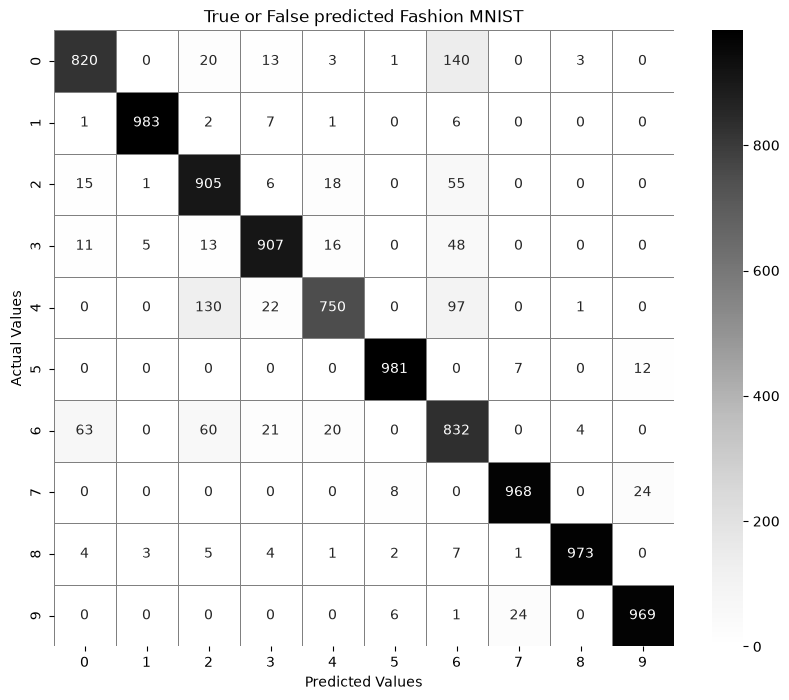

In [30]:
cm = confusion_matrix(y_actual, y_predicted)
plt.figure(figsize=(10, 8))
sns.heatmap(
    cm,
    annot=True,
    cmap='Greys',
    fmt='d',
    linewidths=0.5,
    linecolor='gray'
)
plt.title('True or False predicted Fashion MNIST')
plt.xlabel('Predicted Values')
plt.ylabel('Actual Values')
plt.show()

In [40]:
from sklearn.metrics import classification_report
print(classification_report(y_actual, y_predicted))

              precision    recall  f1-score   support

           0       0.90      0.82      0.86      1000
           1       0.99      0.98      0.99      1000
           2       0.80      0.91      0.85      1000
           3       0.93      0.91      0.92      1000
           4       0.93      0.75      0.83      1000
           5       0.98      0.98      0.98      1000
           6       0.70      0.83      0.76      1000
           7       0.97      0.97      0.97      1000
           8       0.99      0.97      0.98      1000
           9       0.96      0.97      0.97      1000

    accuracy                           0.91     10000
   macro avg       0.91      0.91      0.91     10000
weighted avg       0.91      0.91      0.91     10000



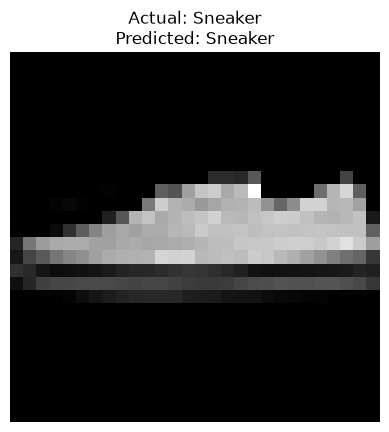

In [39]:
mnist_names = [
    "T-shirt/top","Trouser","Pullover","Dress","Coat","Sandal","Shirt","Sneaker","Bag","Ankle boot"
]	
index = 789
actual = y_test_digit[index]
predicted = np.argmax(y_predict[index])
plt.imshow(x_test_digit[index].reshape(28, 28), cmap='gray')
plt.title(
    f"Actual: {mnist_names[actual]}\n"
    f"Predicted: {mnist_names[predicted]}"
)
plt.axis('off')
plt.show()
